# Exercícios — Algoritmos de Ordenação — Parte I
## Implementação em C e análise experimental com Python

Nesta atividade, os algoritmos de ordenação serão **implementados em linguagem C**. O Python será usado como uma segunda ferramenta: ele permitirá **ler os resultados produzidos pelo programa C, organizar os dados e gerar gráficos**.

### Objetivos
Ao final desta atividade, você deverá ser capaz de:

- implementar **Bubble Sort, Insertion Sort e Selection Sort em C**;
- trabalhar com vetores, funções, ponteiros e estruturas (`struct`) em C;
- verificar se um algoritmo de ordenação está correto antes de medir seu desempenho;
- medir **tempo de execução, número de comparações e número de trocas/movimentações**;
- salvar resultados experimentais em um arquivo **CSV**;
- usar Python para abrir arquivos, manipular dados com `pandas` e produzir gráficos com `matplotlib`;
- relacionar os resultados experimentais com a análise assintótica dos algoritmos.

> **Importante:** primeiro verifique a correção do algoritmo. Somente depois realize os experimentos de desempenho.

## 1. Como executar C dentro do Google Colab

Embora o Colab execute Python por padrão, também podemos criar e compilar programas em C.

Usaremos três recursos:

1. `%%writefile nome.c` — comando especial do notebook que grava o conteúdo da célula em um arquivo;
2. `!gcc ...` — o caractere `!` permite executar um comando do sistema operacional a partir do notebook;
3. `!./programa` — executa o programa C compilado.

Assim, o notebook servirá como um ambiente integrado: **editamos C, compilamos, executamos e depois analisamos os resultados com Python**.

## 2. Arquivo de apoio compartilhado pelos algoritmos

Para acompanhar também o comportamento interno dos algoritmos, vamos registrar:

- `comparacoes`: quantas comparações entre elementos foram realizadas;
- `trocas`: quantas trocas ou movimentações relevantes foram realizadas.

Essas medidas são interessantes porque o tempo depende do computador, enquanto o número de operações está diretamente ligado ao comportamento do algoritmo.

In [1]:
%%writefile ordenacao.h
#ifndef ORDENACAO_H
#define ORDENACAO_H

typedef struct {
    long long comparacoes;
    long long trocas;
} Estatisticas;

void bubble_sort(int v[], int n, Estatisticas *est);
void insertion_sort(int v[], int n, Estatisticas *est);
void selection_sort(int v[], int n, Estatisticas *est);

#endif

Writing ordenacao.h


# Exercício Prático 1 — Bubble Sort

No notebook original, o pseudocódigo denominado `bubbleSortOtimizado` compara `L[i]` diretamente com vários elementos posteriores. Nesta adaptação utilizaremos a forma convencional do **Bubble Sort otimizado**, baseada na comparação entre elementos adjacentes.

Pseudocódigo, usando índices de `0` a `n-1`:

```text
BubbleSortOtimizado(L, n)
    para i = 0 até n-2
        trocou = falso

        para j = 0 até n-i-2
            comparar L[j] com L[j+1]

            se L[j] > L[j+1]
                trocar L[j] e L[j+1]
                trocou = verdadeiro

        se trocou == falso
            parar
```

### Sua tarefa

Complete a função C abaixo. Além da ordenação:

- incremente `est->comparacoes` sempre que dois elementos forem comparados;
- incremente `est->trocas` sempre que dois elementos forem efetivamente trocados.

O teste utilizará vetores aleatórios pequenos antes de qualquer experimento de desempenho.

In [2]:
%%writefile bubble_impl.c
#include "ordenacao.h"

void bubble_sort(int v[], int n, Estatisticas *est) {
    /* TODO:
       1. implemente o Bubble Sort otimizado;
       2. conte comparações em est->comparacoes;
       3. conte trocas em est->trocas.
    */
}

Writing bubble_impl.c


In [3]:
%%writefile teste_bubble.c
#include <stdio.h>
#include <stdlib.h>
#include <time.h>
#include "ordenacao.h"

int esta_ordenado(const int v[], int n) {
    for (int i = 1; i < n; i++)
        if (v[i - 1] > v[i])
            return 0;
    return 1;
}

void imprime_vetor(const int v[], int n) {
    for (int i = 0; i < n; i++)
        printf("%d ", v[i]);
    printf("\n");
}

int main(void) {
    const int tamanhos[] = {5, 10, 15};
    const int qtd = 3;

    srand(42);

    for (int k = 0; k < qtd; k++) {
        int n = tamanhos[k];
        int *v = malloc(n * sizeof(int));

        for (int i = 0; i < n; i++)
            v[i] = 10 + rand() % 91;  // valores entre 10 e 100

        Estatisticas est = {0, 0};

        printf("\nVetor original (n=%d):\n", n);
        imprime_vetor(v, n);

        bubble_sort(v, n, &est);

        printf("Vetor após Bubble Sort:\n");
        imprime_vetor(v, n);

        printf("Ordenado corretamente? %s\n",
               esta_ordenado(v, n) ? "SIM" : "NAO");
        printf("Comparacoes: %lld | Trocas: %lld\n",
               est.comparacoes, est.trocas);

        free(v);
    }

    return 0;
}

Writing teste_bubble.c


In [32]:
!gcc -Wall -Wextra -O2 -std=c11 bubble_impl.c teste_bubble.c -o ./teste_bubble
!./teste_bubble


Vetor original (n=5):
99 47 62 56 59 
Vetor inicial: 
99 47 62 56 59 
Vetor final: 
99 99 99 99 99 

Vetor após Bubble Sort:
99 99 99 99 99 
Ordenado corretamente? SIM
Comparacoes: 7 | Trocas: 4

Vetor original (n=10):
67 34 97 28 10 33 61 82 58 65 
Vetor inicial: 
67 34 97 28 10 33 61 82 58 65 
Vetor final: 
67 67 97 97 97 97 97 97 97 97 

Vetor após Bubble Sort:
67 67 97 97 97 97 97 97 97 97 
Ordenado corretamente? SIM
Comparacoes: 23 | Trocas: 14

Vetor original (n=15):
56 51 16 66 66 33 37 77 82 16 67 19 94 96 100 
Vetor inicial: 
56 51 16 66 66 33 37 77 82 16 67 19 94 96 100 
Vetor final: 
56 56 56 66 66 66 66 77 82 82 82 82 94 96 100 

Vetor após Bubble Sort:
56 56 56 66 66 66 66 77 82 82 82 82 94 96 100 
Ordenado corretamente? SIM
Comparacoes: 41 | Trocas: 13


### Questões para discussão

1. O que acontece com o Bubble Sort otimizado quando o vetor já está ordenado?
2. Por que a variável `trocou` permite encerrar o algoritmo antecipadamente?
3. O número de comparações depende da organização inicial do vetor?
4. O número de trocas depende da organização inicial do vetor?

# Exercício Prático 2 — Insertion Sort

Implemente em C o **Insertion Sort**.

Pseudocódigo adaptado para índices de `0` a `n-1`:

```text
InsertionSort(L, n)
    para j = 1 até n-1
        chave = L[j]
        i = j - 1

        enquanto i >= 0 e L[i] > chave
            L[i+1] = L[i]
            i = i - 1

        L[i+1] = chave
```

### Observação sobre a contagem

Considere como `comparacoes` as comparações relevantes entre elementos do vetor, como `L[i] > chave`. Use `trocas` como contador de movimentações de elementos. Seja consistente no critério utilizado.

In [1]:
%%writefile insertion_impl.c
#include "ordenacao.h"

void insertion_sort(int v[], int n, Estatisticas *est) {
    /* TODO:
       implemente o Insertion Sort e atualize as estatísticas.
    */
}

Writing insertion_impl.c


In [2]:
%%writefile teste_insertion.c
#include <stdio.h>
#include <stdlib.h>
#include <time.h>
#include "ordenacao.h"

int esta_ordenado(const int v[], int n) {
    for (int i = 1; i < n; i++)
        if (v[i - 1] > v[i])
            return 0;
    return 1;
}

int main(void) {
    const int tamanhos[] = {5, 10, 15};
    srand(42);

    for (int k = 0; k < 3; k++) {
        int n = tamanhos[k];
        int *v = malloc(n * sizeof(int));

        for (int i = 0; i < n; i++)
            v[i] = 10 + rand() % 91;

        Estatisticas est = {0, 0};
        insertion_sort(v, n, &est);

        printf("n=%d | correto=%s | comparacoes=%lld | movimentacoes=%lld\n",
               n,
               esta_ordenado(v, n) ? "SIM" : "NAO",
               est.comparacoes,
               est.trocas);

        free(v);
    }

    return 0;
}

Writing teste_insertion.c


In [24]:
!gcc -Wall -Wextra -O3 -std=c11 insertion_impl.c teste_insertion.c -o teste_insertion
!./teste_insertion

Vetor inicial: 
99 47 62 56 59 
Vetor final: 
47 56 59 62 99 

n=5 | correto=SIM | comparacoes=6 | movimentacoes=10
Vetor inicial: 
67 34 97 28 10 33 61 82 58 65 
Vetor final: 
10 28 33 34 58 61 65 67 82 97 

n=10 | correto=SIM | comparacoes=21 | movimentacoes=30
Vetor inicial: 
56 51 16 66 66 33 37 77 82 16 67 19 94 96 100 
Vetor final: 
16 16 19 33 37 51 56 66 66 67 77 82 94 96 100 

n=15 | correto=SIM | comparacoes=30 | movimentacoes=44


# Exercício Prático 3 — Selection Sort

Implemente em C o **Selection Sort**.

```text
SelectionSort(L, n)
    para i = 0 até n-2
        min = i

        para j = i+1 até n-1
            se L[min] > L[j]
                min = j

        se min != i
            trocar L[i] e L[min]
```

Durante a implementação, observe uma característica importante: mesmo quando o vetor já está ordenado, o Selection Sort ainda precisa procurar o menor elemento restante.

In [25]:
%%writefile selection_impl.c
#include "ordenacao.h"

void selection_sort(int v[], int n, Estatisticas *est) {
    /* TODO:
       implemente o Selection Sort e atualize as estatísticas.
    */
}

Writing selection_impl.c


In [26]:
%%writefile teste_selection.c
#include <stdio.h>
#include <stdlib.h>
#include "ordenacao.h"

int esta_ordenado(const int v[], int n) {
    for (int i = 1; i < n; i++)
        if (v[i - 1] > v[i])
            return 0;
    return 1;
}

int main(void) {
    const int tamanhos[] = {5, 10, 15};
    srand(42);

    for (int k = 0; k < 3; k++) {
        int n = tamanhos[k];
        int *v = malloc(n * sizeof(int));

        for (int i = 0; i < n; i++)
            v[i] = 10 + rand() % 91;

        Estatisticas est = {0, 0};
        selection_sort(v, n, &est);

        printf("n=%d | correto=%s | comparacoes=%lld | trocas=%lld\n",
               n,
               esta_ordenado(v, n) ? "SIM" : "NAO",
               est.comparacoes,
               est.trocas);

        free(v);
    }

    return 0;
}

Writing teste_selection.c


In [39]:
!gcc -Wall -Wextra -O2 -std=c11 selection_impl.c teste_selection.c -o teste_selection
!./teste_selection

Vetor inicial: 
99 47 62 56 59 
Vetor final: 
47 56 59 62 99 

n=5 | correto=SIM | comparacoes=10 | trocas=4
Vetor inicial: 
67 34 97 28 10 33 61 82 58 65 
Vetor final: 
10 28 33 34 58 61 65 67 82 97 

n=10 | correto=SIM | comparacoes=45 | trocas=7
Vetor inicial: 
56 51 16 66 66 33 37 77 82 16 67 19 94 96 100 
Vetor final: 
16 16 19 33 37 51 56 66 66 67 77 82 94 96 100 

n=15 | correto=SIM | comparacoes=105 | trocas=10


# Exercício Prático 4 — Experimento comparativo em C

Agora os três algoritmos serão executados para entradas:

- **aleatórias**;
- **já ordenadas**;
- **ordenadas em ordem inversa**.

O programa C abaixo usa as implementações que você produziu nos arquivos:

- `bubble_impl.c`;
- `insertion_impl.c`;
- `selection_impl.c`.

Os resultados serão gravados em `resultados_parte1.csv`.

Cada linha armazenará:

```text
algoritmo,n,tipo,execucao,tempo_us,comparacoes,trocas
```

Antes de registrar um resultado, o programa verifica se o vetor realmente ficou ordenado. Portanto, **o experimento só deve ser executado depois que os três testes anteriores indicarem `SIM`**.

> Para que a atividade seja rápida durante o desenvolvimento, usamos 5 repetições. Depois de validar o código, altere `REPETICOES` para 10 e compare a estabilidade das médias.

In [30]:
%%writefile benchmark_parte1.c
#include <stdio.h>
#include <stdlib.h>
#include <string.h>
#include <time.h>
#include "ordenacao.h"

#define REPETICOES 5

typedef void (*Algoritmo)(int [], int, Estatisticas *);

int esta_ordenado(const int v[], int n) {
    for (int i = 1; i < n; i++)
        if (v[i - 1] > v[i])
            return 0;
    return 1;
}

void gera_entrada(int v[], int n, const char *tipo) {
    if (strcmp(tipo, "ordenado") == 0) {
        for (int i = 0; i < n; i++)
            v[i] = i;
    } else if (strcmp(tipo, "inverso") == 0) {
        for (int i = 0; i < n; i++)
            v[i] = n - i;
    } else {
        for (int i = 0; i < n; i++)
            v[i] = rand();
    }
}

double mede_tempo_us(Algoritmo algoritmo, int v[], int n,
                     Estatisticas *est) {
    clock_t inicio = clock();
    algoritmo(v, n, est);
    clock_t fim = clock();

    return 1e6 * (double)(fim - inicio) / CLOCKS_PER_SEC;
}

int main(void) {
    const int tamanhos[] = {500, 1000, 1500, 2000, 3000};
    const int nt = sizeof(tamanhos) / sizeof(tamanhos[0]);

    const char *tipos[] = {"aleatorio", "ordenado", "inverso"};

    const char *nomes[] = {"bubble", "insertion", "selection"};
    Algoritmo algoritmos[] = {bubble_sort, insertion_sort, selection_sort};

    FILE *arq = fopen("resultados_parte1.csv", "w");
    if (!arq) {
        perror("Nao foi possivel criar o CSV");
        return 1;
    }

    fprintf(arq,
            "algoritmo,n,tipo,execucao,tempo_us,comparacoes,trocas\n");

    srand(42);

    for (int a = 0; a < 3; a++) {
        for (int t = 0; t < 3; t++) {
            for (int s = 0; s < nt; s++) {
                int n = tamanhos[s];

                int *base = malloc(n * sizeof(int));
                int *v = malloc(n * sizeof(int));

                gera_entrada(base, n, tipos[t]);

                for (int r = 1; r <= REPETICOES; r++) {
                    memcpy(v, base, n * sizeof(int));

                    Estatisticas est = {0, 0};
                    double tempo = mede_tempo_us(
                        algoritmos[a], v, n, &est);

                    if (!esta_ordenado(v, n)) {
                        fprintf(stderr,
                                "ERRO: %s nao ordenou corretamente "
                                "(n=%d, tipo=%s).\n",
                                nomes[a], n, tipos[t]);
                        fclose(arq);
                        free(base);
                        free(v);
                        return 2;
                    }

                    fprintf(arq, "%s,%d,%s,%d,%.3f,%lld,%lld\n",
                            nomes[a], n, tipos[t], r, tempo,
                            est.comparacoes, est.trocas);
                }

                free(base);
                free(v);
            }
        }
    }

    fclose(arq);
    printf("Resultados gravados em resultados_parte1.csv\n");
    return 0;
}

Writing benchmark_parte1.c


In [40]:
!gcc -Wall -Wextra -O3 -std=c11 \
    bubble_impl.c insertion_impl.c selection_impl.c \
    benchmark_parte1.c -o benchmark_parte1

!./benchmark_parte1

Vetor inicial: 
71876166 708592740 1483128881 907283241 442951012 537146758 1366999021 1854614940 647800535 53523743 783815874 1643643143 682599717 291474504 229233696 1633529762 175389892 1183169448 1212580698 1596161259 2108313867 469976352 975807809 1113801033 1232315727 1192349579 1564541169 1350496504 1709672141 1253520176 590056433 1781548307 1962112916 2073185314 541347900 257580280 462848424 1908346921 2112195221 1110648960 1961870665 748527447 606808455 496986734 1040001951 836042151 2130516497 1215391843 2019211600 1195613547 664069454 1980041819 1665589900 1639877263 946359204 750421979 684743195 363416725 2100918483 246931688 1616936901 543491269 2028479995 1431566170 469192935 422344247 1689146450 932041360 183207520 1653858023 2042690320 2145078185 254901822 502015127 494581272 1294903773 1338057278 477614121 362811969 1209785230 1673227668 1026881423 1042343401 1191333920 519275039 1988702605 1941755899 1204018234 204635682 1895190735 1450949922 1821572584 291198356 1331

# 5. Python: primeiros passos com arquivos

A partir deste ponto, **o algoritmo continua sendo C**, mas a análise será feita em Python.

Um arquivo CSV é um arquivo de texto no qual cada linha representa um registro e as colunas são separadas por vírgulas.

Python possui a função `open()` para abrir arquivos:

```python
open("nome_do_arquivo", "r")
```

O modo `"r"` significa **read** (leitura).

Usaremos `with` porque ele garante que o arquivo seja fechado automaticamente após o uso:

```python
with open("arquivo.csv", "r") as arquivo:
    ...
```

O método `readline()` lê uma linha por vez. Já `readlines()` pode carregar todas as linhas.

Execute a célula seguinte e observe que estamos lendo diretamente o arquivo produzido pelo programa C.

In [41]:
with open("resultados_parte1.csv", "r") as arquivo:
    for _ in range(6):
        print(arquivo.readline().strip())

algoritmo,n,tipo,execucao,tempo_us,comparacoes,trocas
bubble,500,aleatorio,1,160.000,3303,2585
bubble,500,aleatorio,2,136.000,3303,2585
bubble,500,aleatorio,3,134.000,3303,2585
bubble,500,aleatorio,4,222.000,3303,2585
bubble,500,aleatorio,5,239.000,3303,2585


## 5.1 `pathlib`: verificando se um arquivo existe

A biblioteca `pathlib` oferece uma forma moderna de trabalhar com nomes e caminhos de arquivos.

```python
from pathlib import Path
```

`Path("arquivo.csv")` cria um objeto que representa aquele arquivo. O método `.exists()` informa se ele existe.

Esse tipo de verificação é útil antes de tentar ler resultados produzidos por outro programa.

In [42]:
from pathlib import Path

arquivo_resultados = Path("resultados_parte1.csv")

print("Arquivo encontrado?", arquivo_resultados.exists())
print("Tamanho em bytes:", arquivo_resultados.stat().st_size)

Arquivo encontrado? True
Tamanho em bytes: 9907


# 6. Python: lendo o CSV com `pandas`

Para análises de dados, abrir o CSV linha a linha funciona, mas se torna trabalhoso rapidamente.

A biblioteca **pandas** facilita essa tarefa.

A instrução:

```python
import pandas as pd
```

importa a biblioteca e cria o apelido `pd`, que é uma convenção amplamente utilizada.

Em seguida:

```python
df = pd.read_csv("resultados_parte1.csv")
```

lê o CSV e cria um **DataFrame**.

Um `DataFrame` pode ser entendido, inicialmente, como uma tabela com:

- linhas;
- colunas;
- nomes para as colunas;
- diferentes tipos de dados.

O método `head()` mostra as primeiras linhas da tabela.

In [44]:
import pandas as pd

df = pd.read_csv("resultados_parte1.csv")

display(df.head())
print("\nNúmero de linhas:", len(df))
print("\nTipos das colunas:")
print(df.dtypes)

,algoritmo,n,tipo,execucao,tempo_us,comparacoes,trocas
0,bubble,500,aleatorio,1,160.0,3303,2585
1,bubble,500,aleatorio,2,136.0,3303,2585
2,bubble,500,aleatorio,3,134.0,3303,2585
3,bubble,500,aleatorio,4,222.0,3303,2585
4,bubble,500,aleatorio,5,239.0,3303,2585



Número de linhas: 225

Tipos das colunas:
algoritmo          str
n                int64
tipo               str
execucao         int64
tempo_us       float64
comparacoes      int64
trocas           int64
dtype: object


## 6.1 Selecionando linhas e colunas

Uma coluna pode ser acessada assim:

```python
df["tempo_us"]
```

Também podemos filtrar linhas usando uma condição booleana:

```python
df[df["tipo"] == "aleatorio"]
```

A expressão `df["tipo"] == "aleatorio"` produz uma sequência de valores `True` e `False`. O `pandas` usa essa sequência para manter apenas as linhas que satisfazem a condição.

In [45]:
aleatorios = df[df["tipo"] == "aleatorio"]

display(
    aleatorios[["algoritmo", "n", "tempo_us", "comparacoes", "trocas"]]
    .head(10)
)

,algoritmo,n,tempo_us,comparacoes,trocas
0,bubble,500,160.0,3303,2585
1,bubble,500,136.0,3303,2585
2,bubble,500,134.0,3303,2585
3,bubble,500,222.0,3303,2585
4,bubble,500,239.0,3303,2585
5,bubble,1000,313.0,4849,3622
6,bubble,1000,492.0,4849,3622
7,bubble,1000,486.0,4849,3622
8,bubble,1000,254.0,4849,3622
9,bubble,1000,258.0,4849,3622


## 6.2 Calculando médias com `groupby`

Como cada experimento foi repetido várias vezes, queremos calcular o desempenho **médio**.

O método `groupby()` cria grupos de linhas que possuem os mesmos valores em determinadas colunas.

Por exemplo:

```python
df.groupby(["algoritmo", "n", "tipo"])
```

agrupa os dados por algoritmo, tamanho da entrada e tipo da entrada.

Depois, `.agg(...)` permite calcular estatísticas para cada grupo. Usaremos:

- `mean` — média;
- `std` — desvio-padrão.

`reset_index()` transforma novamente os identificadores dos grupos em colunas normais.

In [46]:
resumo = (
    df.groupby(["algoritmo", "n", "tipo"])
      .agg(
          tempo_medio_us=("tempo_us", "mean"),
          desvio_tempo_us=("tempo_us", "std"),
          comparacoes_medias=("comparacoes", "mean"),
          trocas_medias=("trocas", "mean"),
      )
      .reset_index()
)

display(resumo.head(12))

,algoritmo,n,tipo,tempo_medio_us,desvio_tempo_us,comparacoes_medias,trocas_medias
0,bubble,500,aleatorio,178.2,49.195528,3303.0,2585.0
1,bubble,500,inverso,100.4,18.875911,997.0,499.0
2,bubble,500,ordenado,90.6,7.893035,499.0,0.0
3,bubble,1000,aleatorio,360.6,119.527403,4849.0,3622.0
4,bubble,1000,inverso,213.0,31.543621,1997.0,999.0
5,bubble,1000,ordenado,292.4,106.486149,999.0,0.0
6,bubble,1500,aleatorio,460.4,79.039863,8637.0,6544.0
7,bubble,1500,inverso,396.4,39.411927,2997.0,1499.0
8,bubble,1500,ordenado,299.8,22.365151,1499.0,0.0
9,bubble,2000,aleatorio,605.8,128.818477,18427.0,15799.0


# 7. Python: construindo gráficos com `matplotlib`

A biblioteca **matplotlib** é uma das ferramentas básicas de visualização em Python.

Usaremos:

```python
import matplotlib.pyplot as plt
```

O apelido `plt` também é uma convenção.

Algumas funções importantes:

- `plt.figure(...)` — cria uma nova figura;
- `plt.plot(x, y, ...)` — desenha uma curva;
- `plt.xlabel(...)` e `plt.ylabel(...)` — definem os nomes dos eixos;
- `plt.title(...)` — adiciona um título;
- `plt.legend()` — mostra a legenda;
- `plt.grid()` — adiciona uma grade;
- `plt.show()` — exibe o gráfico.

No código abaixo, o `for` percorre os nomes dos algoritmos. Para cada algoritmo, filtramos as linhas correspondentes e construímos uma curva.

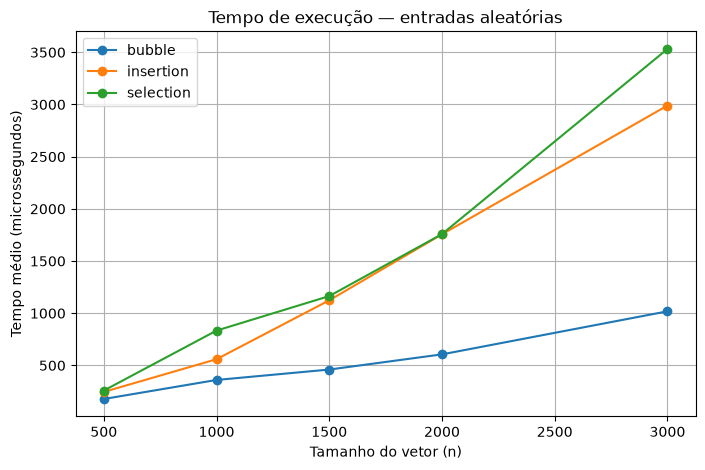

In [47]:
import matplotlib.pyplot as plt

dados = resumo[resumo["tipo"] == "aleatorio"]

plt.figure(figsize=(8, 5))

for algoritmo in dados["algoritmo"].unique():
    parte = dados[dados["algoritmo"] == algoritmo]
    plt.plot(
        parte["n"],
        parte["tempo_medio_us"],
        marker="o",
        label=algoritmo
    )

plt.xlabel("Tamanho do vetor (n)")
plt.ylabel("Tempo médio (microssegundos)")
plt.title("Tempo de execução — entradas aleatórias")
plt.legend()
plt.grid()
plt.show()

## 7.1 Comparações em vez de tempo

O mesmo procedimento pode ser usado para representar o número de comparações.

Esse gráfico é particularmente útil porque diminui a influência de fatores externos da máquina e permite comparar melhor os resultados com a análise assintótica.

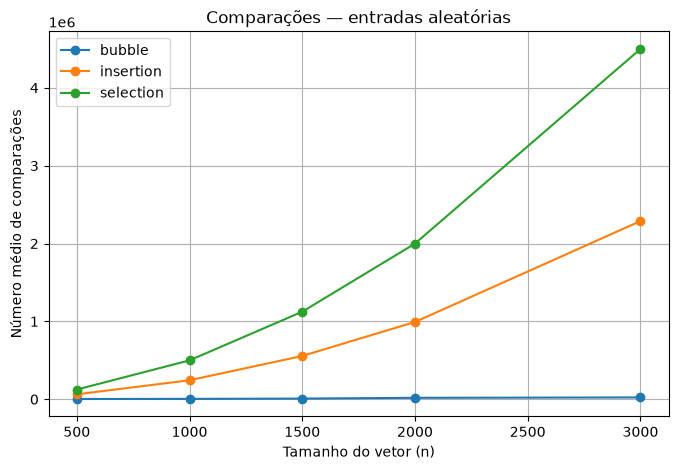

In [48]:
plt.figure(figsize=(8, 5))

for algoritmo in dados["algoritmo"].unique():
    parte = dados[dados["algoritmo"] == algoritmo]
    plt.plot(
        parte["n"],
        parte["comparacoes_medias"],
        marker="o",
        label=algoritmo
    )

plt.xlabel("Tamanho do vetor (n)")
plt.ylabel("Número médio de comparações")
plt.title("Comparações — entradas aleatórias")
plt.legend()
plt.grid()
plt.show()

# 8. Questões de análise

Responda com base nos seus experimentos.

1. Qual algoritmo foi mais rápido para entradas aleatórias?
2. O comportamento observado é compatível com a complexidade assintótica esperada?
3. Compare Bubble Sort, Insertion Sort e Selection Sort para entradas já ordenadas.
4. Repita a comparação para entradas em ordem inversa.
5. Qual algoritmo apresentou maior diferença entre melhor e pior situação?
6. O Selection Sort alterou significativamente o número de comparações entre os três tipos de entrada? Explique.
7. Por que medir somente tempo de execução pode ser insuficiente para comparar algoritmos?
8. Aumente `REPETICOES` de 5 para 10. As médias mudam muito? E o desvio-padrão?

## Desafio opcional em Python

Crie um gráfico que compare, **para cada algoritmo**, os três tipos de entrada (`aleatorio`, `ordenado` e `inverso`).

Sugestão de estratégia:

1. escolha um algoritmo;
2. filtre o `DataFrame`;
3. percorra os três valores da coluna `tipo`;
4. gere uma curva para cada tipo;
5. repita para os demais algoritmos.